[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch04-short_workbook.ipynb)

# `cat`, `dog` and `mat` by the company they keep

The lecture's three sentences are `the cat sat on the mat`,
`the dog sat on the rug` and `the cat chased the dog`. Is `dog` or `mat`
closer to `cat`, and what does a computer count to decide?

In [1]:
#@title Setup: run this cell first
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

SENTENCES = ["the cat sat on the mat", "the dog sat on the rug", "the cat chased the dog"]
WORDS = sorted(set(" ".join(SENTENCES).split()))  # the eight different words, one column each
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8})


def row(word):  # how often each word stands one position before or after a use of `word`
    counts = np.zeros(len(WORDS))
    for s in SENTENCES:
        ws = s.split()
        for i, w in enumerate(ws):
            if w == word:
                for j in (i - 1, i + 1):
                    if 0 <= j < len(ws):
                        counts[WORDS.index(ws[j])] += 1
    return counts


def one_hot(word):  # a 1 in the word's own column, 0 everywhere else
    return np.eye(len(WORDS))[WORDS.index(word)]


def cosine(a, b):  # the dot product over the product of the two lengths
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))


def compare(pairs, use_one_hot):  # the cosine of each pair of words, printed and drawn as bars
    vec = one_hot if use_one_hot else row
    values = [cosine(vec(a), vec(b)) for a, b in pairs]
    for (a, b), v in zip(pairs, values):
        print(f"{a} and {b}: cosine {v:.3f}")
    fig, ax = plt.subplots(figsize=(6, 1.8), layout="constrained")
    bars = ax.barh([f"{a}, {b}" for a, b in pairs], values, color="C0")
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=8)
    ax.set(xlim=(0, 1.15), xlabel="cosine", title="one-hot vectors" if use_one_hot else "neighbour rows")
    ax.invert_yaxis()
    plt.show()

## 1. A word's company is a row of counts

A word's row counts the words one position before and after each of its uses,
with one column for each of the eight words. Run the cell: which neighbours
does `cat` share with `dog`, and which with `mat`? Then add `"rug"` to `SHOW`
and run it again.

In [2]:
SHOW = ["cat", "dog", "mat"]
for word in SHOW:
    print(f"{word:>4}:", {w: int(n) for w, n in zip(WORDS, row(word)) if n})

 cat: {'chased': 1, 'sat': 1, 'the': 2}
 dog: {'sat': 1, 'the': 2}
 mat: {'the': 1}


### Solution

In [3]:
display(Markdown("`cat` stands after `the` twice, before `sat` once and before `chased` once. `dog` shares `the` and `sat` "
                 "with it; `mat` shares only `the`. `rug` has the same row as `mat`: both end a sentence after `the`."))

`cat` stands after `the` twice, before `sat` once and before `chased` once. `dog` shares `the` and `sat` with it; `mat` shares only `the`. `rug` has the same row as `mat`: both end a sentence after `the`.

## 2. Cosine compares two rows by their angle

The cosine of two rows is 1 when they point the same way and 0 when they have
no column in common. Run the cell: is `dog` or `mat` closer to `cat`? Then set
`ONE_HOT` to `True`, which gives each word a single 1 in its own column, and
run it again.

cat and dog: cosine 0.913
cat and mat: cosine 0.816


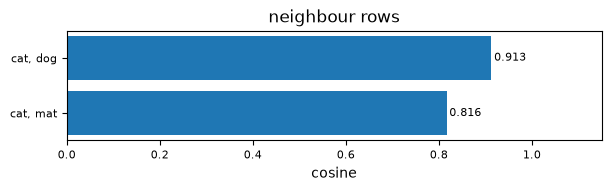

In [4]:
PAIRS = [("cat", "dog"), ("cat", "mat")]
ONE_HOT = False
compare(PAIRS, ONE_HOT)

### Solution

In [5]:
dog, mat = cosine(row("cat"), row("dog")), cosine(row("cat"), row("mat"))
display(Markdown(f"Counted company puts `dog` closer to `cat`: {dog:.3f} against {mat:.3f}. One-hot vectors give "
                 f"{cosine(one_hot('cat'), one_hot('dog')):g} for `dog` and {cosine(one_hot('cat'), one_hot('mat')):g} for "
                 "`mat`: two different words share no column, so one-hot vectors cannot say which is closer."))

Counted company puts `dog` closer to `cat`: 0.913 against 0.816. One-hot vectors give 0 for `dog` and 0 for `mat`: two different words share no column, so one-hot vectors cannot say which is closer.